# Challenge: Wie zuverlässig unterscheidet ein Modell **3** und **8**?

## Python- und Machine-Learning-Grundlagen für unseren Workshop

In den nächsten **etwa 55 Minuten** führen wir eine kompakte
Bildklassifikationsstudie durch. Wir wollen nicht möglichst viel Code lernen,
sondern anhand echter Modellausgaben drei Fragen beantworten:

1. **What?** Was macht das Modell mit unseren Bildern?
2. **So What?** Woran erkennen wir, ob sein Ergebnis gut oder problematisch ist?
3. **Now What?** Was müssen wir im biomedizinischen Hauptversuch genauer prüfen?

Am Ende kannst du zentrale Codezeilen selbst ergänzen, Vorhersagen lesen und
erklären, warum eine einzige Erfolgszahl nicht genügt.

> **Euer Auftrag:** Arbeitet wie ein kleines unabhängiges Modell-Audit. Prüft
> Behauptungen anhand von Daten, unterscheidet Messung und Interpretation und
> notiert, welche zusätzliche Evidenz ihr verlangen würdet. Nicht das Modell
> mit der größten Zahl gewinnt, sondern die am besten begründete Bewertung.

> **Wichtig:** Die Ziffern sind ein überschaubares Lernbeispiel. Auch der spätere
> Gewebedatensatz ist ein Lehrdatensatz – unser Modell ist kein medizinisches
> Diagnosewerkzeug.


## Challenge-Board und Arbeitsweise

**Kernpfad (etwa 55 min):** Folge den acht Abschnitten mit der Kennzeichnung `KERN`.  
**Vertiefung (+15 min):** `OPTIONAL` kennzeichnet Nachschlage- und Zusatzmaterial.

Der Kernpfad enthält sechs **Code-Challenges** mit insgesamt 15 kurzen Checks.
`✓` markiert einen gelösten Check; `↻` bedeutet, dass du die Antwort direkt
überarbeiten kannst. Arbeitet zu zweit und wechselt nach jeder Challenge die
Rollen: Eine Person steuert den Code, die andere prüft Ergebnis und Begründung.
Es geht nicht um Punkte oder Geschwindigkeit, sondern um belastbare Evidenz.

Wir gehen in drei Schritten vor:

1. **Darstellung verstehen:** Wie werden Bild, Daten und Modell in Code sichtbar?
2. **Behauptungen prüfen:** Was sagen Kurven, Konfidenz, Metriken und Loss wirklich?
3. **Auf Medizin übertragen:** Welche Evidenz fehlt vor einer verantwortbaren Nutzung?

### Inhaltsübersicht

1. [Python kompakt: Variablen und Funktionen](#1-python-gibt-dingen-namen)
2. [Ein Bild ist ein Zahlenfeld](#2-ein-bild-ist-ein-zahlenfeld)
3. [Fair prüfen: drei Rollen für Daten](#3-fair-prüfen-drei-rollen-für-daten)
4. [Das Modell lernt](#4-das-modell-lernt)
5. [Eine Vorhersage ist eine Verteilung](#5-eine-vorhersage-ist-kein-etikett-sondern-eine-verteilung)
6. [Mehrere Kennzahlen](#6-gute-gesamtzahl-schlechte-einzelfehler)
7. [Loss und Focal Loss](#7-der-loss-entscheidet-worauf-das-modell-reagiert)
8. [Transfer Learning](#8-transfer-learning-nicht-bei-null-anfangen)

In Jupyter enthält jede Zelle entweder Text oder Code:

- Starte eine Codezelle mit **Shift + Enter**.
- Arbeite von oben nach unten.
- Ein `↻` ist kein Fehler: Es bedeutet, dass du deine Antwort noch verändern kannst.
- Unter jeder Code-Challenge findest du zuerst einen Hinweis und danach eine
  einklappbare Musterlösung.

Wenn etwas technisch scheitert, melde dich. Das Notebook besitzt einen lokalen
Ersatzlauf; niemand soll wegen der Hardware aus dem Experiment fallen.

Die erste lange Codezelle ist vorbereitete Infrastruktur. Führe sie aus; du
musst ihre Imports noch nicht verstehen. Eigene Eingaben stehen später nur an
den deutlich markierten `TODO`-Stellen.


In [ ]:
# KERN · Vorbereitung: Diese Zelle einmal ausführen
import os
import sys
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

orte = [Path.cwd(), Path.cwd().parent]
PROJEKT_ROOT = next((ort for ort in orte if (ort / "src").exists()), None)
if PROJEKT_ROOT is None:
    raise RuntimeError("Bitte den vollständigen Workshop- oder Schülerordner in VS Code öffnen.")
if str(PROJEKT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJEKT_ROOT))

import numpy as np
import tensorflow as tf

# Das Mini-Experiment ist bewusst auf CPU-Laptops ausgelegt. Das vermeidet
# herstellerspezifische GPU-Warnungen und macht den Workshop robuster.
try:
    tf.config.set_visible_devices([], "GPU")
except RuntimeError:
    pass

from src.grundlagen import (
    KLASSENNAMEN,
    berechne_grundlagenmetriken,
    bereite_bilder_vor,
    lade_grundlagen_ergebnisse,
    lade_mnist_grundlagen,
    pruefe_antwort,
    trainiere_grundlagenmodell,
    zeige_beispielbilder,
    zeige_datenaufteilung,
    zeige_fit_muster,
    zeige_konfusionsmatrix,
    zeige_trainingsverlauf,
    zeige_transfer_learning,
    zeige_vorhersage,
)

np.random.seed(313)
tf.keras.utils.set_random_seed(313)
print(f"✓ Bereit – Python {sys.version_info.major}.{sys.version_info.minor}, TensorFlow {tf.__version__}")


<a id="1-python-gibt-dingen-namen"></a>
## 1. Python kompakt: Variablen und Funktionen · KERN 1/8 · etwa 6 Minuten

### What?

Eine **Variable** ist ein Name für einen Wert. Python erkennt den Datentyp aus
dem Wert. Listen speichern eine veränderbare Reihenfolge, Tupel eine feste
Zusammenstellung und Dictionaries ordnen Schlüsseln passende Werte zu.


In [ ]:
anzahl_bilder = 1800                         # ganze Zahl (int)
lernrate = 0.001                             # Kommazahl (float)
frage = "Ist das eine 3 oder eine 8?"        # Text (str)
training_fertig = False                      # Wahrheitswert (bool)
klassen_namen = ["3", "8"]                 # Liste
bildform = (28, 28)                          # Tupel
versuch = {"epochen": 4, "batch": 64}      # Dictionary

print(frage)
print("Klassen:", klassen_namen)
print("Versuchsplan:", versuch)


Eine **Funktion** erledigt eine klar benannte Aufgabe. In
`len(klassen_namen)` ist `len` der Funktionsname und `klassen_namen` das
**Argument**. Der **Rückgabewert** wird hier in `anzahl_klassen` gespeichert.


In [ ]:
anzahl_klassen = len(klassen_namen)
print("Die Funktion len(...) gibt zurück:", anzahl_klassen)


### Code-Challenge 1/6 – Das zweite Element auswählen

Python zählt Positionen ab **0**. Ändere nur den Index in der nächsten Zelle,
sodass `zweite_klasse` den Text `"8"` enthält.


In [ ]:
zweite_klasse = klassen_namen[0]  # TODO: Index ändern
pruefe_antwort("Aufgabe 1", zweite_klasse, "8")


<details>
<summary>Hinweis anzeigen</summary>

Das erste Element hat den Index `0`. Welchen Index hat dann das zweite?
</details>

<details>
<summary>Musterlösung zur Selbstkontrolle anzeigen</summary>

```python
zweite_klasse = klassen_namen[1]
pruefe_antwort("Aufgabe 1", zweite_klasse, "8")
```
</details>


### So What? / Now What?

Modelle geben später nicht direkt den Text „8“ aus, sondern Zahlen an
bestimmten Positionen. Deshalb brauchen wir Indizes. Als Nächstes sehen wir,
wie ein Bild selbst zu Zahlen wird.


<a id="2-ein-bild-ist-ein-zahlenfeld"></a>
## 2. Ein Bild ist ein Zahlenfeld · KERN 2/8 · etwa 4 Minuten

### What?

Für den Computer ist ein Graustufenbild ein **NumPy-Array**: 28 Zeilen mal
28 Spalten mit Helligkeitswerten von 0 (schwarz) bis 255 (weiß).


In [ ]:
daten = lade_mnist_grundlagen(PROJEKT_ROOT)
zeige_beispielbilder(daten["x_train"], daten["y_train"])

erstes_bild = daten["x_train"][0]
print("Form des Bildes:", erstes_bild.shape)
print("Datentyp:", erstes_bild.dtype)
print("Kleiner Ausschnitt:\n", erstes_bild[10:15, 10:15])


### Code-Challenge 2/6 – Die Form auslesen

Ersetze das Startertupel durch die Eigenschaft, die Python gerade oben
ausgegeben hat.


In [ ]:
gemessene_bildform = (0, 0)  # TODO: Form von erstes_bild auslesen
pruefe_antwort("Aufgabe 2", gemessene_bildform, (28, 28))


<details>
<summary>Hinweis anzeigen</summary>

Die Form eines Arrays steht in seiner Eigenschaft `.shape`.
</details>

<details>
<summary>Musterlösung zur Selbstkontrolle anzeigen</summary>

```python
gemessene_bildform = erstes_bild.shape
pruefe_antwort("Aufgabe 2", gemessene_bildform, (28, 28))
```
</details>


### So What? / Now What?

Ein Modell sieht keine „3“, sondern ein Muster aus Zahlen. Wenn wir Bilder
falsch skalieren oder verdrehen, verändern wir also seine Information. Im
Hauptversuch ist das Preprocessing deshalb fertig vorbereitet.


<a id="3-fair-prüfen-drei-rollen-für-daten"></a>
## 3. Fair prüfen: drei Rollen für Daten · KERN 3/8 · etwa 4 Minuten

### What?

- **Training:** Das Modell passt seine Parameter an.
- **Validierung:** Wir beobachten während der Entwicklung, ob die Leistung auf
  zurückgehaltene Beispiele übertragbar ist.
- **Test:** Ein versiegelter Umschlag – erst am Ende öffnen.


In [ ]:
zeige_datenaufteilung(daten)


### So What? / Now What?

Wer Testbilder zum Üben oder Auswählen benutzt, kennt die Prüfungsfragen schon.
Das Ergebnis wirkt dann besser, als es auf wirklich unbekannten Bildern wäre.
Unser Mini-Modell sieht die Testdaten erst nach dem Training.


<a id="4-das-modell-lernt"></a>
## 4. Das Modell lernt · KERN 4/8 · etwa 10 Minuten

### What?

Unser kleines **Convolutional Neural Network (CNN)** sucht zunächst einfache
Bildmerkmale wie Kanten. Ein **Loss** misst den Fehler. Der Optimierer verändert
die Modellparameter so, dass dieser Loss kleiner wird. Eine **Epoche** bedeutet:
Das Modell hat alle Trainingsbilder einmal verarbeitet.

Bevor du startest: Wird der Validierungs-Loss eher sinken oder steigen?


In [ ]:
try:
    modell, verlauf = trainiere_grundlagenmodell(daten, epochs=4, batch_size=64)
    test_wahrscheinlichkeiten = modell.predict(
        bereite_bilder_vor(daten["x_test"]), verbose=0
    )
    ergebnis_herkunft = "selbst trainiert"
    print("✓ Training abgeschlossen.")
except Exception as fehler:
    print("Das Training war auf diesem Gerät nicht möglich:", type(fehler).__name__)
    modell, verlauf, test_wahrscheinlichkeiten = lade_grundlagen_ergebnisse(PROJEKT_ROOT)
    ergebnis_herkunft = "vorbereiteter Ersatzlauf"

zeige_trainingsverlauf(verlauf)
print("Ergebnisquelle:", ergebnis_herkunft)


### Was zeigen Training und Validierung?

Sinkt der Loss, macht das Modell beim gemessenen Fehlermaß Fortschritte.
Die Validierung zeigt, ob sich das auch auf anderen Bildern auszahlt.
Ein **Checkpoint** ist ein gespeicherter Modellstand, etwa nach einer Epoche.

| Muster | Was zeigen die Kurven? | Was könnt ihr prüfen? |
| --- | --- | --- |
| **Underfitting** | Training und Validierung bleiben schwach. | Lernt das Modell mit mehr Zeit oder anderen Einstellungen besser? |
| **Passende Lernphase** | Beide Kurven zeigen gute Werte. | Modellstand anhand der Validierung auswählen und später auf Testbildern prüfen. |
| **Overtraining** | Das Training verbessert sich weiter. Die Validierung war gut und wird wieder schlechter. | Einen früheren, guten Checkpoint wählen. |
| **Overfitting ohne brauchbaren Checkpoint im gezeigten Lauf** | Das Training wird gut. Die Validierung bleibt im Vergleich schwach. | Ein kleineres Modell mit denselben Daten vergleichen. |

Im letzten Fall kann das Modell für die verfügbaren Daten zu flexibel sein
und Besonderheiten der Trainingsbilder lernen. Ob die Modellgröße dazu
beiträgt, lässt sich mit einem gezielten Vergleich prüfen.

Die nächste Abbildung zeigt vier **schematische Verläufe** auf derselben Skala.
Die Messwerte eures Ziffernmodells stehen direkt über diesem Abschnitt.


In [ ]:
zeige_fit_muster()


### Lernkurven vergleichen

Begründet zu zweit mit **beiden** Kurven der schematischen Abbildung:

1. Bei welchem Verlauf würdet ihr einen früheren Modellstand auswählen und aus welcher Epoche?
2. Wo könnte längeres Training noch helfen? Was würdet ihr in den Kurven beobachten?
3. **Optional:** Wie würdet ihr prüfen, ob ein kleineres Modell auf denselben Bildern besser verallgemeinert?

<details>
<summary>Mögliche Antworten</summary>

1. Beim Overtraining ist die Validierung in Epoche 4 am besten. Danach sinkt nur der Trainings-Loss weiter.
2. Beim Underfitting sind beide Loss-Werte noch hoch. Prüft, ob mehr Epochen den Loss in beiden Kurven senken.
3. Verwendet dieselbe Datenaufteilung und vergleichbare Trainingsbedingungen. Wiederholt die Läufe mit verschiedenen Zufallsstarts. Vergleicht für beide Modelle jeweils den Modellstand mit dem besten Validierungswert.

</details>


<details>
<summary>OPTIONAL · Forschungsnotiz: Warum „größer = schlechter“ zu einfach ist</summary>

Sehr große Netze können Trainingsdaten sogar mit zufälligen Labels auswendig
lernen. Trotzdem steigt der Fehler auf neuen Daten mit wachsender Modellgröße
nicht immer gleichmäßig: Beim **Double Descent** kann er nach einem kritischen
Bereich erneut sinken. Beim **Grokking** wird erst der Trainingssatz beherrscht
und die Generalisierung verbessert sich überraschend viel später – also gerade
nicht „Underfitting kippt in Overfitting“.

Solche Effekte sind keine Ausrede für ein schlechtes Ergebnis. Man benötigt
kontrollierte Größenvergleiche, mehrere Wiederholungen und unabhängige
Testdaten:

- [Zhang et al.: *Understanding deep learning requires rethinking generalization*](https://arxiv.org/abs/1611.03530)
- [Nakkiran et al.: *Deep Double Descent*](https://arxiv.org/abs/1912.02292)
- [Power et al.: *Grokking: Generalization Beyond Overfitting*](https://arxiv.org/abs/2201.02177)

</details>


<a id="5-eine-vorhersage-ist-kein-etikett-sondern-eine-verteilung"></a>
## 5. Eine Vorhersage ist kein Etikett, sondern eine Verteilung · KERN 5/8 · etwa 7 Minuten

### What?

Für jedes Bild gibt das Modell zwei Werte zwischen 0 und 1 aus, die sich hier
zu 1 addieren. `np.argmax` findet die Position des größten Werts; `np.max`
liefert diesen Wert als **Konfidenz**.

Beispiel: Das Modell gibt für `[3, 8]` die Werte `[0.30, 0.70]` aus. Es sagt
also **8** mit **70 % Konfidenz**. Ist das wahre Label aber 3, ist diese
Vorhersage trotz der 70 % falsch. Konfidenz beschreibt die Ausgabe des Modells;
**Korrektheit** kennen wir erst nach dem Vergleich mit dem wahren Label. Ohne
zusätzliche Prüfung dürfen wir 70 % Konfidenz nicht als „70 % Wahrscheinlichkeit,
dass das Modell recht hat“ lesen.

Für die nächsten Aufgaben reichen zwei Python-Regeln:

- `=` speichert einen Wert; `==` vergleicht zwei Werte und liefert `True` oder
  `False`.
- `>=` bedeutet „größer oder gleich“ und übersetzt hier das Wort „mindestens“.
- `if bedingung:` führt den eingerückten Block nur aus, wenn die Bedingung
  `True` ist; `else:` beschreibt den anderen Fall.


In [ ]:
beispiel_index = 0
beispiel_wahrscheinlichkeiten = test_wahrscheinlichkeiten[beispiel_index]
wahres_label = int(daten["y_test"][beispiel_index])
zeige_vorhersage(
    daten["x_test"][beispiel_index],
    beispiel_wahrscheinlichkeiten,
    wahres_label,
)
print("Zahlen des Modells:", np.round(beispiel_wahrscheinlichkeiten, 3))


### Code-Challenge 3/6 – Klasse, Konfidenz und Korrektheit

Nutze für das feste Übungsbeispiel `np.argmax`, `np.max` und `==`.


In [ ]:
uebungs_wahrscheinlichkeiten = np.array([0.22, 0.78])
uebungs_label = 1

vorhergesagte_klasse = 0       # TODO: Position des größten Werts
konfidenz = 0.0                # TODO: größten Wert bestimmen
ist_korrekt = False            # TODO: Klasse und Label vergleichen

pruefe_antwort("Aufgabe 3a", vorhergesagte_klasse, 1)
pruefe_antwort("Aufgabe 3b", konfidenz, 0.78)
pruefe_antwort("Aufgabe 3c", ist_korrekt, True)


<details>
<summary>Hinweis anzeigen</summary>

`argmax` liefert die **Position**, `max` den **Wert**. Vergleiche danach die Position mit `uebungs_label`.
</details>

<details>
<summary>Musterlösung zur Selbstkontrolle anzeigen</summary>

```python
vorhergesagte_klasse = np.argmax(uebungs_wahrscheinlichkeiten)
konfidenz = np.max(uebungs_wahrscheinlichkeiten)
ist_korrekt = vorhergesagte_klasse == uebungs_label
```
</details>


### Code-Challenge 4/6 – Eine Konfidenzschwelle

Ein System könnte eine Vorhersage nur dann automatisch weitergeben, wenn die
Konfidenz mindestens 70 % beträgt. Ergänze Vergleich und `if`-Bedingung. Eine
Schwelle ist dabei keine Reparatur des Modells, sondern eine Regel für den
Umgang mit seinen Ausgaben.


In [ ]:
konfidenz_fuer_schwelle = 0.78
schwelle = 0.70
ist_ueber_schwelle = False  # TODO: feste Konfidenz mit Schwelle vergleichen

if False:                   # TODO: Bedingung einsetzen
    entscheidung = "anzeigen"
else:
    entscheidung = "prüfen lassen"

pruefe_antwort("Aufgabe 4a", ist_ueber_schwelle, True)
pruefe_antwort("Aufgabe 4b", entscheidung, "anzeigen")


<details>
<summary>Hinweis anzeigen</summary>

„Mindestens“ wird in Python mit `>=` geschrieben. Die entstandene boolesche Variable kann direkt hinter `if` stehen.
</details>

<details>
<summary>Musterlösung zur Selbstkontrolle anzeigen</summary>

```python
ist_ueber_schwelle = konfidenz_fuer_schwelle >= schwelle
if ist_ueber_schwelle:
    entscheidung = "anzeigen"
else:
    entscheidung = "prüfen lassen"
```
</details>


### So What? / Now What?

Konfidenz bedeutet: „Wie eindeutig ist die interne Verteilung des Modells?“
Sie bedeutet nicht automatisch: „Wie wahrscheinlich ist das Modell wirklich
korrekt?“ Eine höhere Schwelle kann Fehler unter den automatisch übernommenen
Fällen verringern, stellt aber mehr Fälle zurück. Deshalb berichten wir im
Hauptversuch immer Fehler **und** Anteil der zurückgestellten Fälle.


<a id="6-gute-gesamtzahl-schlechte-einzelfehler"></a>
## 6. Gute Gesamtzahl, schlechte Einzelfehler? · KERN 6/8 · etwa 10 Minuten

### What?

Eine **Konfusionsmatrix** zählt jede Kombination aus wahrem und vorhergesagtem
Label. Die Zeilen sind hier die Wahrheit, die Spalten die Vorhersage:

| 10 Testbilder | vorhergesagt 3 | vorhergesagt 8 |
| --- | ---: | ---: |
| **wahr 3** | 4 | 1 |
| **wahr 8** | 2 | 3 |

Wir betrachten zuerst die **8 als Zielklasse**. Dann sind `TP = 3` richtig
erkannte Achten, `FP = 1` fälschlich als 8 bezeichnete Drei und `FN = 2`
übersehene Achten. `TN = 4` sind richtig erkannte Dreien.

**Kurze Prognose vor dem Rechnen:** Welche Kennzahl reagiert direkt auf die
zwei übersehenen Achten? Entscheidet zu zweit und begründet eure Wahl am
Nenner der Formel. Die Formeln müsst ihr nicht auswendig lernen; wichtig ist,
welche Fälle im Zähler und Nenner stehen.

**Python-Brücke:** `/` bedeutet Division. In Python 3 ergibt `3 / 4` den
Dezimalwert `0.75`. Das ist besonders wichtig, wenn ihr Java kennt: Dort kann
die Division zweier Ganzzahlen stattdessen eine Ganzzahldivision ergeben.
Klammern legen wie in der Mathematik fest, was zuerst berechnet wird.

$$
N=TP+TN+FP+FN
$$

$$
\text{Accuracy}=\frac{TP+TN}{N}
$$

$$
\text{Precision}_8=\frac{TP}{TP+FP}
$$

$$
\text{Recall}_8=\text{Sensitivität}_8=\frac{TP}{TP+FN}
$$

$$
\text{Spezifität}_8=\frac{TN}{TN+FP}
$$

$$
F1_8=2\cdot\frac{\text{Precision}_8\cdot\text{Recall}_8}
{\text{Precision}_8+\text{Recall}_8}
$$

$$
\text{Macro-F1}=\frac{F1_3+F1_8}{2}
$$

- **Accuracy** fragt: Welcher Anteil aller Vorhersagen stimmt?
- **Precision für 8** fragt: Wenn das Modell „8“ sagt – wie oft stimmt das?
- **Recall für 8** fragt: Wie viele der echten Achten findet das Modell?
- **Spezifität für 8** fragt: Wie viele Dreien weist das Modell korrekt zurück?
- **F1 für 8** verbindet Precision und Recall durch das harmonische Mittel.
- Für die Klasse 3 tauschen wir die Perspektive. **Macro-F1** ist der
  Mittelwert der beiden F1-Werte; dadurch zählt jede Klasse gleich viel.


### Code-Challenge 5/6 – Kennzahlen von Hand und im Code ausrechnen

Rechne mit der Tabelle zuerst auf Papier. Ergänze danach die fünf kurzen
Rechenschritte. Für die Klasse 3 ist `F1_3 = 8 / 11 ≈ 0,727` bereits gegeben.


In [ ]:
tp_8, fp_8, fn_8, tn_8 = 3, 1, 2, 4
anzahl_gesamt = 10

accuracy_klein = 0.0   # TODO: (TP + TN) / alle
precision_8 = 0.0      # TODO: TP / (TP + FP)
recall_8 = 0.0         # TODO: TP / (TP + FN)
f1_8 = 0.0             # TODO: 2 * Precision * Recall / (Precision + Recall)
f1_3 = 8 / 11          # für die zweite Perspektive schon ausgerechnet
macro_f1_klein = 0.0   # TODO: Mittelwert aus F1_3 und F1_8

pruefe_antwort("Aufgabe 5a", accuracy_klein, 0.70)
pruefe_antwort("Aufgabe 5b", precision_8, 0.75)
pruefe_antwort("Aufgabe 5c", recall_8, 0.60)
pruefe_antwort("Aufgabe 5d", f1_8, 2 / 3)
pruefe_antwort("Aufgabe 5e", macro_f1_klein, 23 / 33)


<details>
<summary>Hinweis anzeigen</summary>

Beginne mit `accuracy_klein = (tp_8 + tn_8) / anzahl_gesamt`. In den Nennern von Precision und Recall steht jeweils `TP` plus die Fehlerart aus der Formel.
</details>

<details>
<summary>Musterlösung zur Selbstkontrolle anzeigen</summary>

```python
accuracy_klein = (tp_8 + tn_8) / anzahl_gesamt
precision_8 = tp_8 / (tp_8 + fp_8)
recall_8 = tp_8 / (tp_8 + fn_8)
f1_8 = 2 * precision_8 * recall_8 / (precision_8 + recall_8)
macro_f1_klein = (f1_3 + f1_8) / 2
```
</details>


### Kontrolle der Handrechnung

- Accuracy: `(3 + 4) / 10 = 0,70`
- Precision für 8: `3 / (3 + 1) = 0,75`
- Recall für 8: `3 / (3 + 2) = 0,60`
- F1 für 8: `2 · 0,75 · 0,60 / (0,75 + 0,60) ≈ 0,667`
- F1 für 3: `2 · 4 / (2 · 4 + 2 + 1) = 8 / 11 ≈ 0,727`
- Macro-F1: `(0,667 + 0,727) / 2 ≈ 0,697`

Hier ist Accuracy mit 70 % etwas höher als Macro-F1. Vor allem der Recall der
Klasse 8 fällt mit 60 % ab: Zwei von fünf echten Achten wurden übersehen. Erst
diese Einordnung macht aus den Zahlen eine Aussage. Praktisch gewichten
Precision und Recall verschiedene Fehler: Falsche Alarme senken Precision,
übersehene Zielbeispiele senken Recall. Welche Fehler schwerer wiegen, müssen
Menschen für den Anwendungskontext begründen – die Kennzahl entscheidet das
nicht. Auch eine Konfidenzschwelle verändert diese Größen und muss mitgenannt
werden.


In [ ]:
metriken = berechne_grundlagenmetriken(
    daten["y_test"], test_wahrscheinlichkeiten
)
print(f"Accuracy:  {metriken['accuracy']:.1%}")
print(f"Macro-Precision: {metriken['precision']:.1%}")
print(f"Macro-Recall:    {metriken['recall']:.1%}")
print(f"Macro-F1:  {metriken['macro_f1']:.1%}")
zeige_konfusionsmatrix(metriken["confusion_matrix"])


### Von zwei zu zehn Ziffern

Oben seht ihr die Matrix eures Modells für 3 und 8. Die **vollständige
10×10-Matrix** unten zeigt ein vorbereitetes Modell für alle Ziffern von 0 bis 9.
Jedes der 10.000 Bilder aus dem offiziellen MNIST-Testsatz zählt in genau einem
Feld.

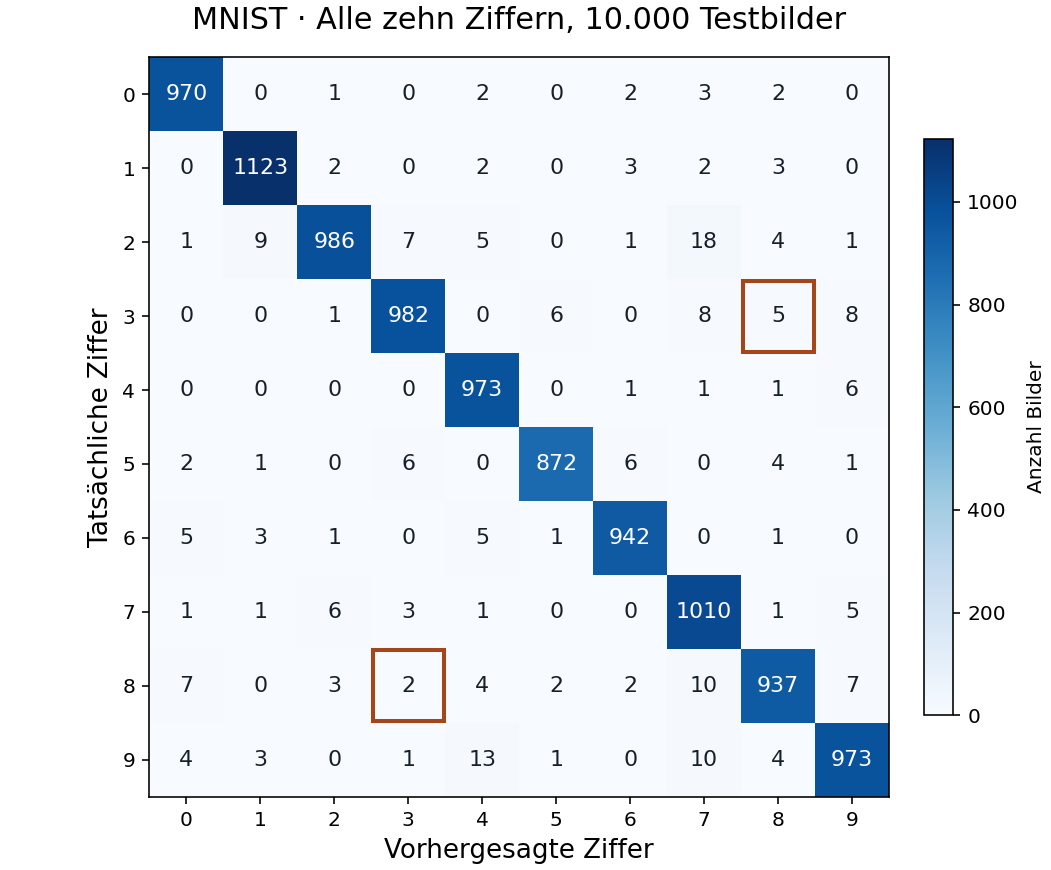

Die Matrix ist als **Heatmap** dargestellt, also als Farbkarte für Zahlen.
Dunkleres Blau bedeutet hier **mehr Bilder im Feld**. Auf der Diagonale stimmen
die beiden Ziffern überein. Alle anderen Felder zeigen Verwechslungen.

- **So lest ihr ein Feld:** Zeile `3`, Spalte `8` bedeutet, dass das Modell
  **5 Dreien** als Achten eingeordnet hat.
- **Jetzt ihr:** Wie viele echte Achten hat das Modell als Dreien eingeordnet?
  Zeigt auf das Feld und nennt die Zahl.

<details>
<summary>Antwort prüfen</summary>

In Zeile `8`, Spalte `3` stehen **2 Bilder**. Die beiden markierten
Felder zählen Verwechslungen in entgegengesetzten Richtungen.

</details>

<a id="7-der-loss-entscheidet-worauf-das-modell-reagiert"></a>
## 7. Der Loss steuert, welche Fehler beim Lernen zählen · KERN 7/8 · etwa 7 Minuten

### What?

Die **Kreuzentropie** nutzt die Wahrscheinlichkeit `p_t`, die das Modell der
wahren Klasse gegeben hat:

$$
\text{Cross-Entropy}=-\ln(p_t)
$$

`ln` ist der natürliche Logarithmus. Für unsere Interpretation genügt: Je
kleiner `p_t`, desto größer die Strafe.

| Wahrscheinlichkeit der wahren Klasse `p_t` | Cross-Entropy `-ln(p_t)` | Bedeutung |
| ---: | ---: | --- |
| 0,90 | 0,105 | sicher und richtig eingeordnet → kleine Strafe |
| 0,50 | 0,693 | unsicher → mittlere Strafe |
| 0,10 | 2,303 | wahre Klasse fast ausgeschlossen → große Strafe |

Der Mittelwert dieser drei Loss-Werte ist:

$$
\overline{L}_{\mathrm{CE}}
=\frac{0{,}105+0{,}693+2{,}303}{3}\approx1{,}034
$$

Beim Training verändert der Optimierer Modellparameter, um einen solchen
mittleren Loss zu verkleinern. **Loss und Metrik sind nicht dasselbe:** Der Loss
steuert das Lernen mit den ganzen Wahrscheinlichkeiten; Accuracy, Precision,
Recall und F1 bewerten anschließend die getroffenen Klassenentscheidungen.

**Focal Loss** multipliziert die Kreuzentropie zusätzlich mit
`(1 - p_t) ** gamma`: Beispiele mit großem `p_t` verlieren viel Einfluss;
Beispiele mit kleinem `p_t` behalten relativ mehr von ihrem
Cross-Entropy-Loss.

Bevor wir die Formel zusammensetzen, probieren wir ihre vier Python-Bausteine
getrennt aus.


In [ ]:
a = tf.constant([0.0, 1.0])
b = tf.constant([0.2, 0.8])

print("elementweise Multiplikation:", a * b)
print("Summe der Elemente:", float(tf.reduce_sum(a * b)))
print("Potenz:", (1 - 0.8) ** 2)
print("Logarithmus:", float(tf.math.log(0.8)))


Für eine einfache Handrechnung setzen wir zunächst `alpha_t = 1` und
`gamma = 2`:

| `p_t` | Cross-Entropy | Fokusfaktor `(1-p_t)^2` | Focal Loss |
| ---: | ---: | ---: | ---: |
| 0,90 | 0,105 | 0,01 | 0,001 |
| 0,50 | 0,693 | 0,25 | 0,173 |
| 0,10 | 2,303 | 0,81 | 1,865 |

Das leichte Beispiel wird stark heruntergewichtet; das schwierige behält
relativ mehr von seinem Cross-Entropy-Loss. `alpha_t` kann zusätzlich Klassen
unterschiedlich gewichten.
Bei `gamma = 0` ist der Fokusfaktor 1 und es bleibt die gewichtete
Kreuzentropie. „Schwierig“ bedeutet dabei nicht automatisch „seltene Klasse“:
Auch falsch gelabelte Bilder oder Ausreißer können stärker zählen.


Jetzt gilt für ein Beispiel mit One-Hot-Label:

$$
p_t=\sum y_{true}\cdot y_{pred},\qquad
\alpha_t=\sum y_{true}\cdot\alpha
$$

$$
\text{Focal Loss}=-\alpha_t(1-p_t)^\gamma\ln(p_t)
$$


### Code-Challenge 6/6 – Die drei Bausteine zusammensetzen

Die wahre Klasse ist hier die zweite Position. Ergänze `p_t`, `alpha_t` und
den Focal-Loss-Term genau nach der Formel.


In [ ]:
y_true = tf.constant([0.0, 1.0])
y_pred = tf.constant([0.2, 0.8])
alpha = tf.constant([0.4, 0.6])
gamma = 2.0

p_t = tf.constant(0.5)       # TODO: y_true und y_pred verbinden
alpha_t = tf.constant(0.5)   # TODO: y_true und alpha verbinden
focal_loss = tf.constant(0.0)  # TODO: Formel einsetzen

erwarteter_loss = -0.6 * (1 - 0.8) ** 2 * np.log(0.8)
pruefe_antwort("Aufgabe 6a", float(p_t), 0.8)
pruefe_antwort("Aufgabe 6b", float(alpha_t), 0.6)
pruefe_antwort("Aufgabe 6c", float(focal_loss), erwarteter_loss)


<details>
<summary>Hinweis anzeigen</summary>

Für `p_t` und `alpha_t`: elementweise multiplizieren und mit `tf.reduce_sum(...)` addieren. Danach die Formel Zeile für Zeile übertragen.
</details>

<details>
<summary>Musterlösung zur Selbstkontrolle anzeigen</summary>

```python
p_t = tf.reduce_sum(y_true * y_pred)
alpha_t = tf.reduce_sum(y_true * alpha)
focal_loss = -alpha_t * (1 - p_t) ** gamma * tf.math.log(p_t)
```
</details>


### So What? / Now What?

Eine Verlustfunktion ist keine neutrale Rechenvorschrift: Sie legt fest, wie
Verlustbeiträge beim Lernen gewichtet werden. Focal Loss dämpft Beiträge mit
großem `p_t` besonders stark; Beiträge mit kleinem `p_t` bleiben relativ
wichtiger. Das kann bei schwierigen Beispielen helfen, aber auch Ausreißer
relativ stärker betonen. Genau das testen wir später – statt nur anzunehmen,
dass die Methode „fair“ sei.


<a id="8-transfer-learning-nicht-bei-null-anfangen"></a>
## 8. Transfer Learning: Nicht bei null anfangen · KERN 8/8 · etwa 3 Minuten

### What?

Im Hauptversuch nutzen wir MobileNetV2. Dieses Netz hat bereits an vielen
Alltagsbildern allgemeine Merkmale gelernt. Wir frieren den vortrainierten
Rumpf zunächst ein und trainieren einen neuen Kopf für unsere acht Klassen.
Beim **Fine-Tuning** geben wir später vorsichtig einzelne Schichten frei.


In [ ]:
zeige_transfer_learning()


### Eine Heatmap auf einem Bild lesen

Im Hauptversuch nutzen wir **Grad-CAM**, um für eine ausgewählte Klasse
auffällige Regionen im Eingabebild farbig zu markieren. Die Farben beziehen
sich hier auf **Bildstellen**. Warme Farben zeigen in dieser Abbildung,
wo die berechnete Markierung für die Zielklasse stärker ausfällt.

| Originalbild | Grad-CAM für die Zielklasse „Katze“ |
| --- | --- |
| 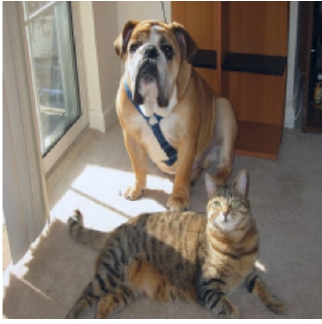 | 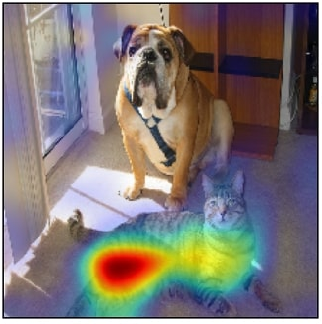 |

**Schaut hin:** Wo liegt die stärkste Markierung? Formuliert eine Vermutung,
welches Bildmerkmal das Modell dort genutzt haben könnte. Ob dieses Merkmal
die Vorhersage beeinflusst, könntet ihr mit einer gezielten Änderung am Bild
prüfen. Im Hauptversuch machen wir diesen Vergleich an Gewebebildern.

*Bildbeispiel: Ausschnitte aus Abb. 1(a) und 1(c), Selvaraju et al.,
[Grad-CAM, arXiv v4 (2019)](https://arxiv.org/abs/1610.02391v4).*

## Abschluss-Checkpoint: Transfer in das Hauptprojekt

Du kannst jetzt:

- Bilder als Arrays und Labels als Indizes lesen,
- Training, Validierung und Test unterscheiden,
- Underfitting und mehrere Overfitting-Muster anhand von Evidenz unterscheiden,
- Klasse, Konfidenz und Korrektheit aus einer Vorhersage bestimmen,
- Accuracy, Precision, Recall beziehungsweise Sensitivität, Spezifität,
  Macro-F1 und Konfusionsmatrix einordnen,
- Cross-Entropy als Trainingssignal von Bewertungsmetriken unterscheiden,
- die drei zentralen Ausdrücke von Focal Loss ergänzen,
- Transfer Learning als „vortrainierter Rumpf + neuer Kopf“ erklären.

### Exit-Ticket

Notiere zu zweit je einen Satz:

1. **What?** Welches Ergebnis unseres Ziffernmodells hat dich überrascht?
2. **So What?** Warum reicht hohe Konfidenz nicht als Vertrauensbeweis?
3. **Now What?** Welche Kennzahl oder welches Fehlerbild willst du im
   biomedizinischen Versuch zuerst untersuchen?

### Ausblick auf den Forschungsauftrag

Im Hauptversuch begegnen dieselben Fragen in anspruchsvollerer Form wieder:
Kann eine hohe Accuracy Fehler einzelner Klassen verdecken? Verschieben
Klassen-Gewichte oder Focal Loss nur die Zahlen – oder auch die Fehler? Und
liefert eine auffällige Heatmap eine Erklärung oder zunächst nur eine neue
Hypothese? Wählt eine dieser Fragen als euren ersten Prüfauftrag.


---

## OPTIONAL · Model Audit: Einen selbstsicheren Fehler analysieren

Eine hohe Gesamtgenauigkeit klingt überzeugend. Aber welches Bild hat das
Modell trotzdem falsch eingeordnet – und bei welchem Fehler war es am
selbstsichersten? Die nächste Zelle sucht genau diesen Fall im Testdatensatz.


In [ ]:
test_vorhersagen = np.argmax(test_wahrscheinlichkeiten, axis=1)
fehler_indices = np.flatnonzero(test_vorhersagen != daten["y_test"])

if len(fehler_indices) > 0:
    fehler_konfidenzen = np.max(test_wahrscheinlichkeiten[fehler_indices], axis=1)
    fehler_index = int(fehler_indices[np.argmax(fehler_konfidenzen)])
    zeige_vorhersage(
        daten["x_test"][fehler_index],
        test_wahrscheinlichkeiten[fehler_index],
        int(daten["y_test"][fehler_index]),
    )
    print("Konfidenz des Fehlers:", f"{np.max(test_wahrscheinlichkeiten[fehler_index]):.1%}")
else:
    print("In diesem Lauf gab es keinen Testfehler. Nutzt den vorbereiteten Ersatzlauf zum Vergleichen.")

print("Auditfrage: Welche zusätzliche Prüfung könnte erklären, warum das Modell hier so sicher falsch liegt?")


## OPTIONAL · Bereitgestellter Code: ansehen, nicht implementieren

Die Trainingsfunktion steht in `src/grundlagen.py`. Diese
Zelle zeigt automatisch die aktuell verwendete Quelle. Du musst sie nicht
verändern; suche beim Lesen nur Modellschichten, Loss und Optimierer.


In [ ]:
import inspect
print(inspect.getsource(trainiere_grundlagenmodell))


# OPTIONAL · Vertiefung und Nachschlagen (+15 Minuten)

## Python-Spickzettel

| Ziel | Beispiel |
| --- | --- |
| Wert speichern | `x = 3` |
| Listenelement wählen | `namen[1]` |
| Arrayform lesen | `bild.shape` |
| größten Wert finden | `np.max(werte)` |
| Position des größten Werts | `np.argmax(werte)` |
| vergleichen | `vorhersage == label` |
| Schwelle prüfen | `konfidenz >= 0.7` |
| Bedingung | `if bedingung:` |
| Elemente multiplizieren | `a * b` |
| Tensorwerte addieren | `tf.reduce_sum(tensor)` |
| natürlicher Logarithmus | `tf.math.log(wert)` |

## Begriffskarte Deutsch – Englisch

| Deutsch | Englisch | Kurz erklärt |
| --- | --- | --- |
| Merkmal | feature | Information, die das Modell nutzt |
| Label | label | vorgegebene Zielklasse |
| Vorhersage | prediction | Ausgabe des Modells |
| Verlust | loss | Fehlermaß für das Training |
| Genauigkeit | accuracy | Anteil korrekter Vorhersagen |
| Genauigkeit der Zielklassen-Treffer | precision | Anteil richtiger Treffer unter den Vorhersagen einer Zielklasse |
| Trefferquote einer Zielklasse | recall | Anteil gefundener Beispiele einer tatsächlichen Zielklasse |
| F1-Wert | F1 score | harmonisches Mittel aus Precision und Recall |
| Makro-Mittel | macro average | Kennzahl je Klasse berechnen, dann gleichgewichtet mitteln |
| Kreuzentropie | cross-entropy | Loss, der kleine Wahrscheinlichkeit für die wahre Klasse stark bestraft |
| Konfidenz | confidence | größter ausgegebener Wahrscheinlichkeitswert |
| Trainingsdurchlauf | epoch | einmal durch alle Trainingsbeispiele |
| Überanpassung | overfitting | Training gelernt, neue Daten schlechter |
| Klassenungleichgewicht | class imbalance | Klassen kommen unterschiedlich häufig vor |
| Übertragungslernen | transfer learning | vorhandene Modellmerkmale weiterverwenden |

### Zusatzbegriffe für biomedizinische Kontexte

Bei zwei Klassen heißt Recall der Zielklasse oft **Sensitivität**. Im
Handbeispiel für die 8 ist sie `3 / 5 = 0,60`. Die **Spezifität** fragt, welcher
Anteil der anderen Klasse korrekt zurückgewiesen wird:

$$
\text{Spezifität}=\frac{TN}{TN+FP}=\frac{4}{4+1}=0{,}80
$$

Bei vielen Klassen betrachten wir jede Klasse nacheinander als Zielklasse.

## Funktionskarten

```python
np.argmax([0.2, 0.8])      # 1: Position des größten Werts
np.max([0.2, 0.8])         # 0.8: größter Wert
tf.reduce_sum([0.2, 0.8])  # 1.0: Summe eines Tensors
tf.math.log(0.8)           # natürlicher Logarithmus
```

### Denkfrage

Ein Modell ist bei einer falschen Vorhersage zu 99 % sicher. Ist diese
Vorhersage dadurch vertrauenswürdiger? Begründe mit den Begriffen
**Konfidenz**, **Korrektheit** und **Testdaten**.
